# SWYNEX Internship — Task 1
## Dataset Exploration & Preprocessing

**Objective:** Explore a real-world dataset, identify data quality issues, handle missing values, analyze distributions, encode categorical variables, and prepare a clean dataset for machine learning.

**Dataset:** IBM Telco Customer Churn

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Imports successful!")

Imports successful!


In [2]:
import certifi
import ssl
from urllib.request import urlretrieve, build_opener, HTTPSHandler, install_opener
from pathlib import Path

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
file_path = data_dir / "Telco-Customer-Churn.csv"

ssl_context = ssl.create_default_context(cafile=certifi.where())
opener = build_opener(HTTPSHandler(context=ssl_context))
install_opener(opener)

if not file_path.exists():
    urlretrieve(url, file_path)

print(f"Dataset saved to: {file_path}")

Dataset saved to: data\Telco-Customer-Churn.csv


In [3]:
import pandas as pd
from pathlib import Path

file_path = Path("data") / "Telco-Customer-Churn.csv"

print("File exists:", file_path.exists())

if file_path.exists():
    df = pd.read_csv(file_path)
    print("Dataset shape:", df.shape)
    display(df.head())

File exists: True
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Statistical summary
print("\nNumerical summary:")
display(df.describe())

print("\nCategorical summary:")
display(df.describe(include="object"))

Number of rows: 7043
Number of columns: 21

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 no

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000



Categorical summary:


C:\Users\91852\AppData\Local\Temp\ipykernel_28632\3576088606.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [5]:
# Missing values
missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": (missing / len(df) * 100).round(2)
})

display(missing_summary[missing_summary["Missing Values"] > 0])

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Unique values per column
display(df.nunique().sort_values().to_frame("Unique Values"))

,Missing Values,Missing Percentage


Duplicate rows: 0


,Unique Values
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Imports successful!")

Imports successful!


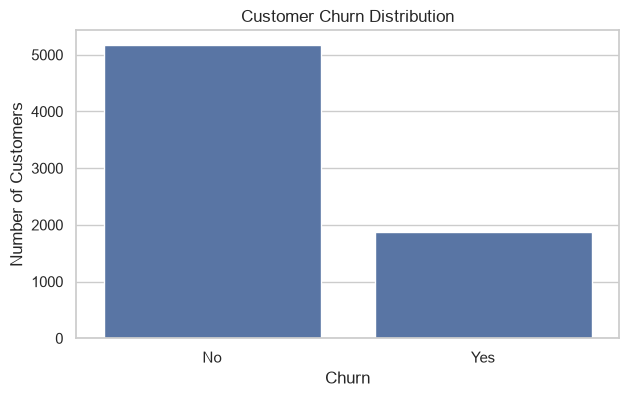

In [7]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

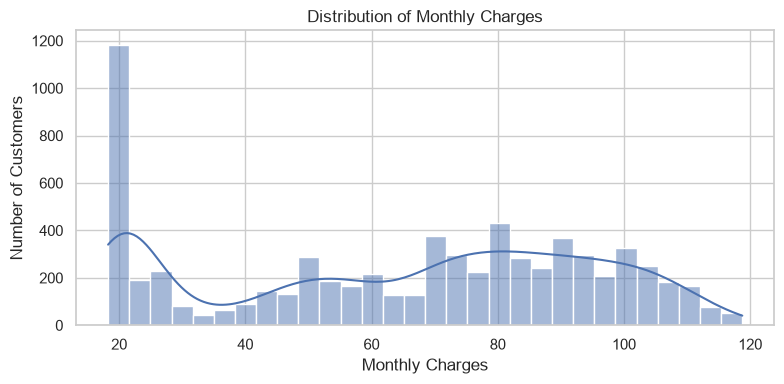

In [8]:
# Distribution of monthly charges
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="MonthlyCharges", bins=30, kde=True)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

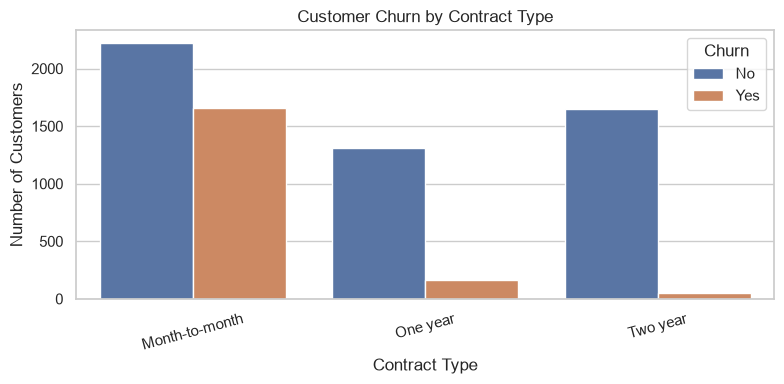

In [9]:
# Customer churn by contract type
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [10]:
# Check missing values in each column
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_summary[missing_summary["Missing Values"] > 0])

,Missing Values,Missing Percentage


In [11]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [12]:
print("Data types:")
display(df.dtypes.to_frame("Data Type"))

print("Unique values in TotalCharges:")
print(df["TotalCharges"].unique()[:20])

print("Target distribution:")
display(df["Churn"].value_counts())

Data types:


,Data Type
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


Unique values in TotalCharges:
<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',  '587.45',   '326.8',  '5681.1',  '5036.3',
 '2686.05', '7895.15', '1022.95', '7382.25',  '528.35',  '1862.9']
Length: 20, dtype: str
Target distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [13]:
# Work on a copy to preserve the original dataset
df_clean = df.copy()

# Convert TotalCharges to numeric; invalid/blank values become NaN
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

print("Missing TotalCharges after conversion:",
      df_clean["TotalCharges"].isnull().sum())

Missing TotalCharges after conversion: 11


In [14]:
# Inspect rows with missing TotalCharges
display(
    df_clean.loc[
        df_clean["TotalCharges"].isna(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [15]:
print("Missing TotalCharges:", df_clean["TotalCharges"].isna().sum())
print("Zero-tenure customers:", (df_clean["tenure"] == 0).sum())
print(
    "Missing TotalCharges with zero tenure:",
    ((df_clean["TotalCharges"].isna()) & (df_clean["tenure"] == 0)).sum()
)

Missing TotalCharges: 11
Zero-tenure customers: 11
Missing TotalCharges with zero tenure: 11


In [16]:
df_clean.loc[
    df_clean["TotalCharges"].isna() & (df_clean["tenure"] == 0),
    "TotalCharges"
] = 0

print("Remaining missing values:", df_clean["TotalCharges"].isna().sum())
print("Cleaned dataset shape:", df_clean.shape)

Remaining missing values: 0
Cleaned dataset shape: (7043, 21)


In [17]:
df_clean.to_csv("data/Telco-Customer-Churn-Cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [18]:
print("Dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())
display(df_clean.head())

Dataset shape: (7043, 21)
Remaining missing values: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [19]:
categorical_cols = df_clean.select_dtypes(include="object").columns.tolist()

print("Categorical columns:", categorical_cols)
print("Number of categorical columns:", len(categorical_cols))

Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
Number of categorical columns: 17


C:\Users\91852\AppData\Local\Temp\ipykernel_28632\2592355569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_clean.select_dtypes(include="object").columns.tolist()


In [20]:
# Remove customerID because it is an identifier, not a useful predictive feature
df_model = df_clean.drop(columns=["customerID"]).copy()

# Separate input features and target
X = df_model.drop(columns=["Churn"])
y = df_model["Churn"].map({"No": 0, "Yes": 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target mapping: No = 0, Yes = 1")

Feature shape: (7043, 19)
Target shape: (7043,)
Target mapping: No = 0, Yes = 1


In [21]:
X_encoded = pd.get_dummies(
    X,
    columns=X.select_dtypes(include="object").columns.tolist(),
    drop_first=True,
    dtype=int
)

print("Encoded feature shape:", X_encoded.shape)
display(X_encoded.head())

Encoded feature shape: (7043, 30)


C:\Users\91852\AppData\Local\Temp\ipykernel_28632\2587426595.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columns=X.select_dtypes(include="object").columns.tolist(),


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0


In [22]:
print("Missing values in features:", X_encoded.isnull().sum().sum())
print("Missing values in target:", y.isnull().sum())
print("Target classes:")
display(y.value_counts())

print("\nFinal feature data types:")
display(X_encoded.dtypes.value_counts())

Missing values in features: 0
Missing values in target: 0
Target classes:


Churn
0    5174
1    1869
Name: count, dtype: int64


Final feature data types:


int64      28
float64     2
Name: count, dtype: int64

In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 30)
Testing features: (1409, 30)
Training target: (5634,)
Testing target: (1409,)


In [24]:
from sklearn.preprocessing import StandardScaler

numeric_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Numerical features scaled successfully.")

Numerical features scaled successfully.


In [25]:
print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())
print("Training class proportions:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).round(3))

Training missing values: 0
Testing missing values: 0
Training class proportions:


Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


Testing class proportions:


Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

In [26]:
from pathlib import Path

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

X_train.to_csv(output_dir / "X_train.csv", index=False)
X_test.to_csv(output_dir / "X_test.csv", index=False)
y_train.to_csv(output_dir / "y_train.csv", index=False)
y_test.to_csv(output_dir / "y_test.csv", index=False)

X_encoded.to_csv(output_dir / "features_encoded.csv", index=False)
y.to_csv(output_dir / "target.csv", index=False)

print("All processed files saved in data/processed/")

All processed files saved in data/processed/


## Conclusion

This project explored and preprocessed the IBM Telco Customer Churn dataset as part of SWYNEX Internship Task 1.

### Key Activities
- Loaded and inspected the dataset structure and feature types.
- Performed exploratory data analysis using statistical summaries and visualizations.
- Checked for missing values and duplicate records.
- Converted `TotalCharges` to numeric and handled missing values associated with zero-tenure customers.
- Encoded categorical features using one-hot encoding and converted the target variable into binary labels.
- Split the data into training and testing sets using stratified sampling.
- Standardized numerical features using statistics learned from the training set only.

### Outcome
The dataset is prepared for subsequent machine-learning experiments. Further work can include training classification models, evaluating performance metrics, and investigating methods to address class imbalance.